In [9]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "src" / "clases_po").exists():
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT / "src"))

from clases_po import HFDatasetLoader

loader = HFDatasetLoader(
    dataset_name="espejelomar/data-science-job-salaries",
    split="train",
    filename="datos/salaries.csv",
)
df = loader.load()

# Estandarizamos nombres de columnas
df.columns = [col.strip() for col in df.columns]
if "Unnamed: 0" in df.columns:
    df = df.drop(columns=["Unnamed: 0"])

df.head(2)

,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,2020,MI,FT,Data Scientist,70000,EUR,79833,DE,0,DE,L
1,2020,SE,FT,Machine Learning Scientist,260000,USD,260000,JP,0,JP,S


In [10]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
import numpy as np

# Preparar datos: Predecir salary_in_usd a partir de remote_ratio
X, y = df[["remote_ratio"]], df["salary_in_usd"]

# Inicializar modelo
modelo = LinearRegression()

# Dividir datos
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Entrenamiento
modelo.fit(X_train, y_train)

# Predicción
predicciones = modelo.predict(X_test)
w = modelo.coef_[0]
b = modelo.intercept_

print(f"MAE: {mean_absolute_error(y_test, predicciones):.2f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, predicciones)):.2f}")
print(f"R2: {r2_score(y_test, predicciones):.2f}")
print(f"w: {w:.2f}")
print(f"b: {b:.2f}")

MAE: 45611.66
RMSE: 60977.35
R2: 0.03
w: 179.58
b: 101436.28


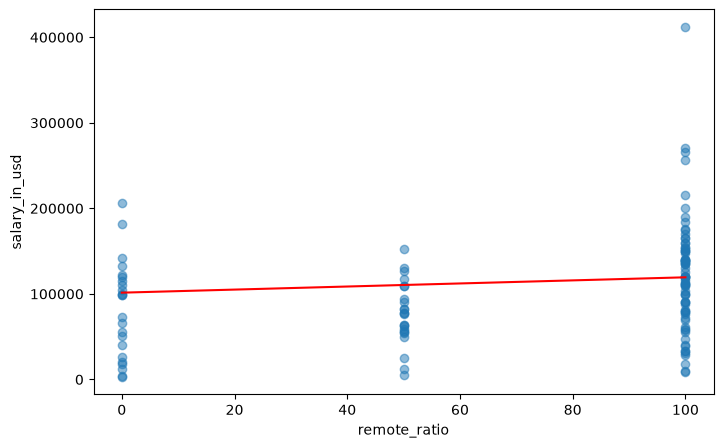

In [11]:
%matplotlib inline
import matplotlib.pyplot as plt
from IPython.display import display

x_test = X_test["remote_ratio"].to_numpy()
y_test_array = y_test.to_numpy()
orden = x_test.argsort()

fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(
    x_test,
    y_test_array,
    alpha=0.5,
)

ax.plot(
    x_test[orden],
    predicciones[orden],
    color="red",
)

ax.set_xlabel("remote_ratio")
ax.set_ylabel("salary_in_usd")

display(fig)
plt.close(fig)

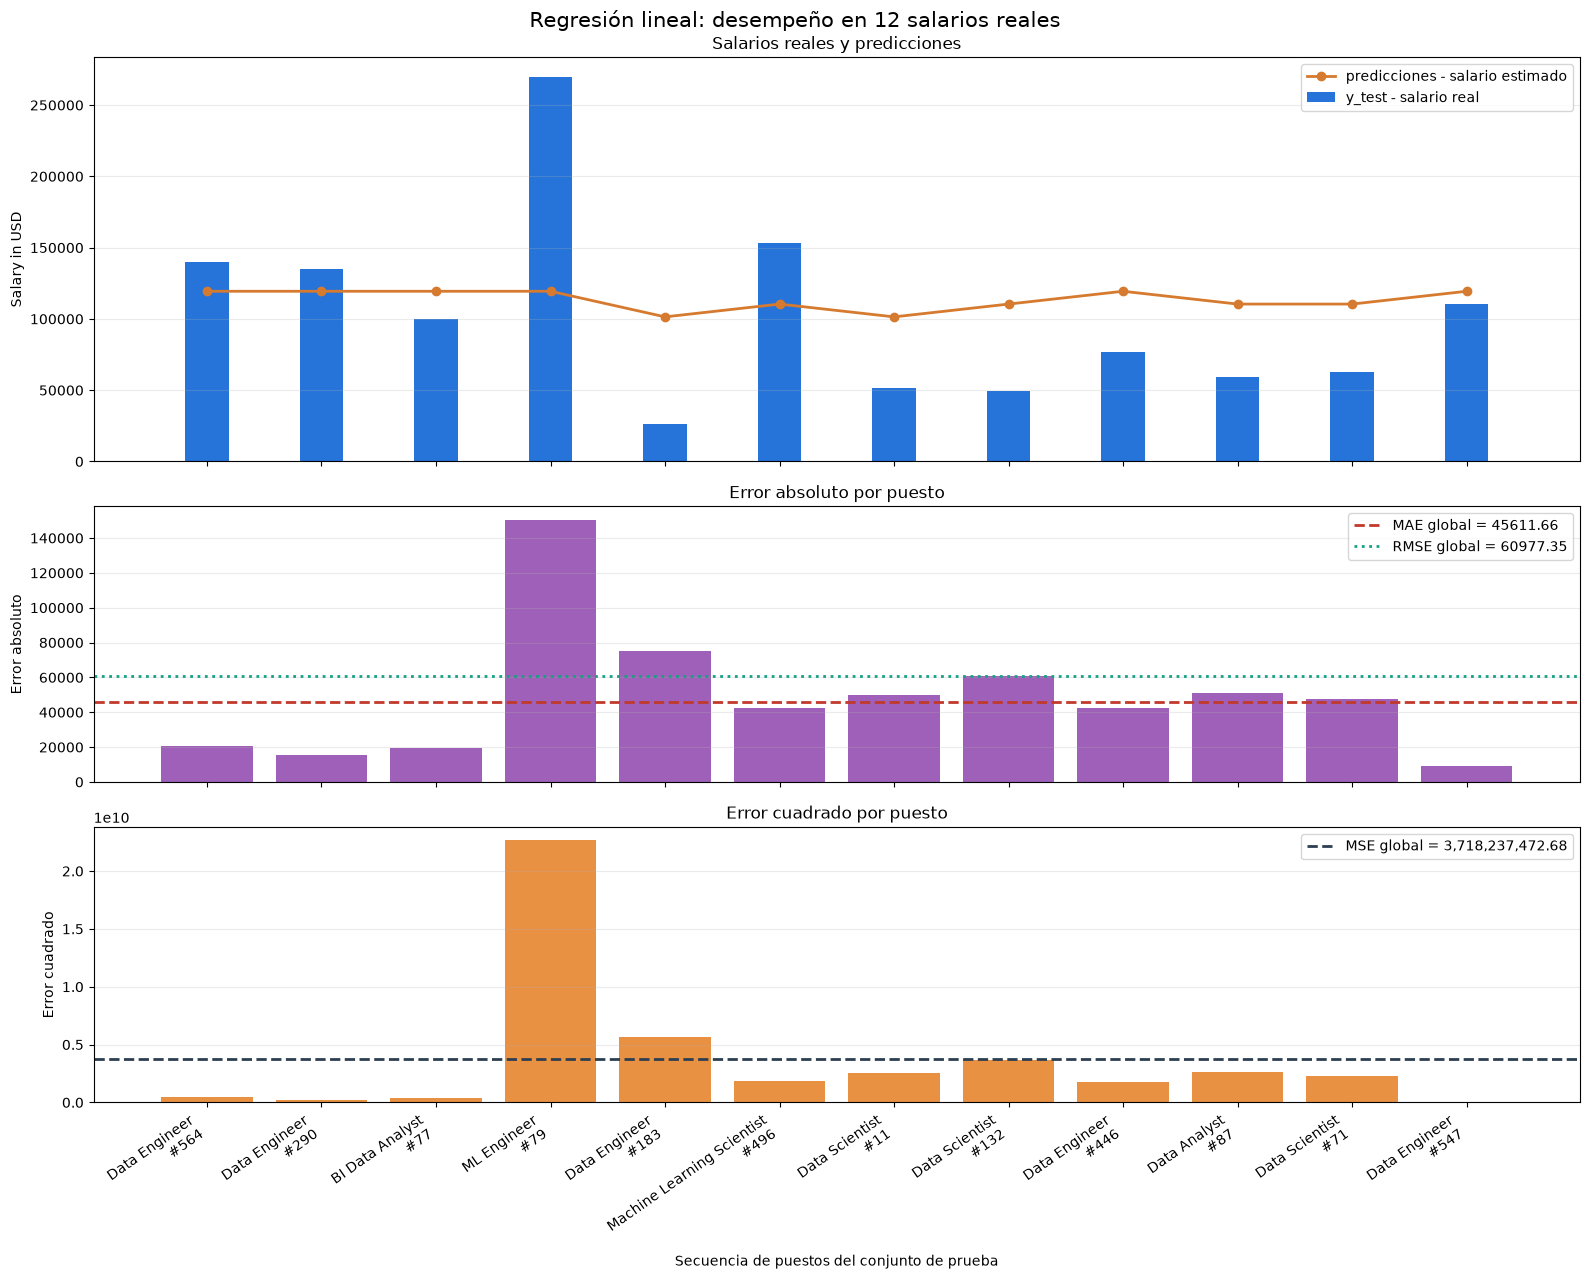

Puestos mostrados: 12 de 122
Métricas globales - MAE: 45611.66; RMSE: 60977.35; MSE: 3,718,237,472.68
Métricas de la selección - MAE: 48809.45; RMSE: 60713.30; MSE: 3,686,105,320.26


In [12]:
# Comparación combinada para una selección legible de salarios reales
indices_test = y_test.index.to_numpy()
y_test_array = y_test.to_numpy()
predicciones_array = np.asarray(predicciones)

# Se muestran 12 salarios, manteniendo el orden del conjunto de prueba
seleccion = np.arange(min(12, len(y_test_array)))
y_real = y_test_array[seleccion]
y_predicha = predicciones_array[seleccion]
errores = y_real - y_predicha
error_absoluto = np.abs(errores)
error_cuadrado = errores ** 2

etiquetas = [
    f"{df.loc[indices_test[i], 'job_title']}\n#{indices_test[i] + 1}"
    for i in seleccion
]

mae_global = mean_absolute_error(y_test_array, predicciones_array)
rmse_global = np.sqrt(mean_squared_error(y_test_array, predicciones_array))
mse_global = mean_squared_error(y_test_array, predicciones_array)
posiciones = np.arange(len(seleccion))
ancho = 0.38

fig, (ax_precios, ax_absoluto, ax_cuadrado) = plt.subplots(
    3, 1, figsize=(16, 13), sharex=True,
    gridspec_kw={"height_ratios": [2.2, 1.5, 1.5]},
)

# Arriba: salario real en barras y predicción como línea con puntos
ax_precios.bar(posiciones, y_real, ancho, label="y_test - salario real", color="#2674d9")
ax_precios.plot(posiciones, y_predicha, color="#d67a2f", marker="o", linewidth=2,
                label="predicciones - salario estimado")
ax_precios.set_ylabel("Salary in USD")
ax_precios.set_title("Salarios reales y predicciones")
ax_precios.legend()
ax_precios.grid(axis="y", alpha=0.25)

# En medio: errores absolutos y referencias globales del modelo
ax_absoluto.bar(posiciones, error_absoluto, color="#8e44ad", alpha=0.85)
ax_absoluto.axhline(mae_global, color="#c0392b", linestyle="--", linewidth=2,
                    label=f"MAE global = {mae_global:.2f}")
ax_absoluto.axhline(rmse_global, color="#16a085", linestyle=":", linewidth=2,
                    label=f"RMSE global = {rmse_global:.2f}")
ax_absoluto.set_ylabel("Error absoluto")
ax_absoluto.set_title("Error absoluto por puesto")
ax_absoluto.legend()
ax_absoluto.grid(axis="y", alpha=0.25)

# Abajo: errores cuadrados y referencia global del MSE
ax_cuadrado.bar(posiciones, error_cuadrado, color="#e67e22", alpha=0.85)
ax_cuadrado.axhline(mse_global, color="#2c3e50", linestyle="--", linewidth=2,
                    label=f"MSE global = {mse_global:,.2f}")
ax_cuadrado.set_ylabel("Error cuadrado")
ax_cuadrado.set_title("Error cuadrado por puesto")
ax_cuadrado.legend()
ax_cuadrado.grid(axis="y", alpha=0.25)

ax_cuadrado.set_xticks(posiciones)
ax_cuadrado.set_xticklabels(etiquetas, rotation=35, ha="right")
ax_cuadrado.set_xlabel("Secuencia de puestos del conjunto de prueba")
fig.suptitle("Regresión lineal: desempeño en 12 salarios reales", fontsize=15)
fig.tight_layout()
display(fig)
plt.close(fig)

print(f"Puestos mostrados: {len(seleccion)} de {len(y_test_array)}")
print(f"Métricas globales - MAE: {mae_global:.2f}; RMSE: {rmse_global:.2f}; MSE: {mse_global:,.2f}")
print(f"Métricas de la selección - MAE: {error_absoluto.mean():.2f}; RMSE: {np.sqrt(error_cuadrado.mean()):.2f}; MSE: {error_cuadrado.mean():,.2f}")

Filas: 607 | duplicados exactos: 42
Valores faltantes por columna:
Sin valores faltantes


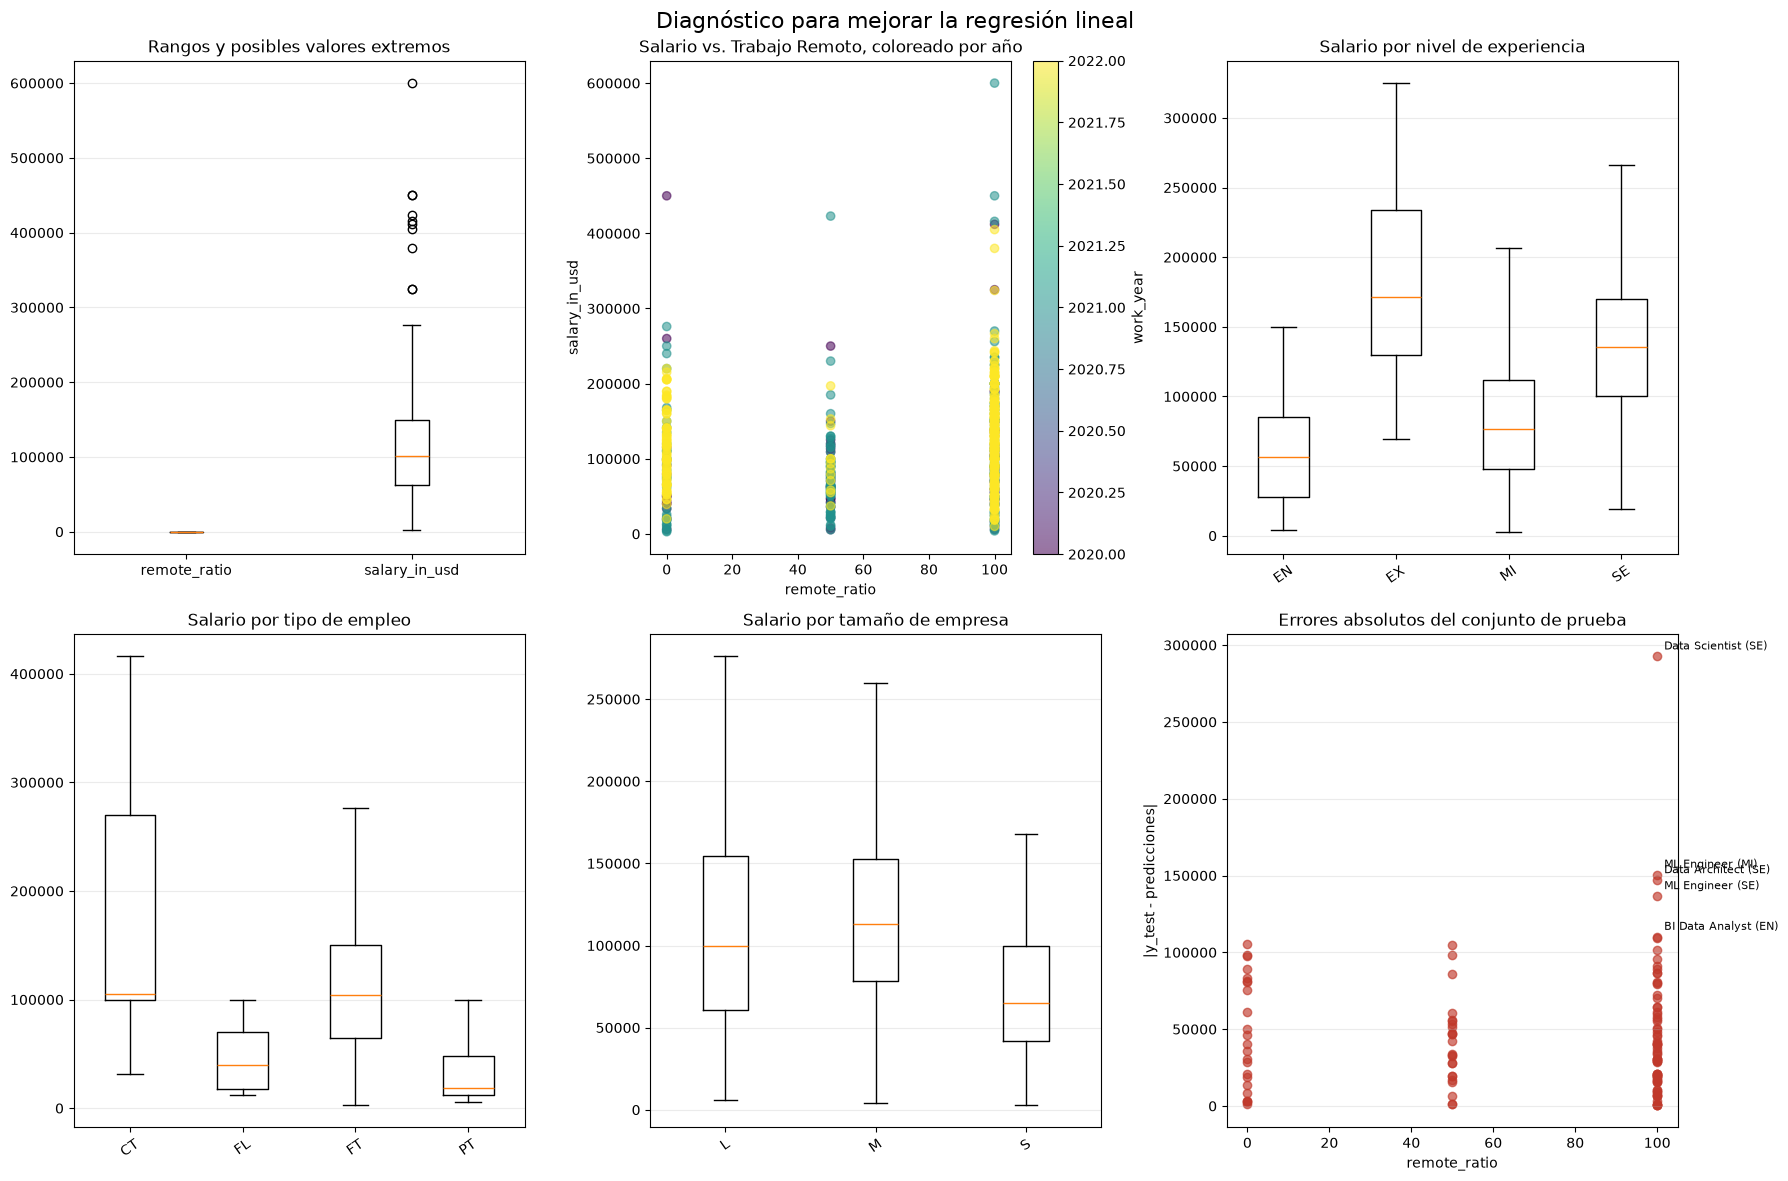


Mayores errores absolutos del conjunto de prueba:
           job_title experience_level  work_year  remote_ratio  y_test   predicciones  error_absoluto
63    Data Scientist               SE       2020           100  412000  119394.572023   292605.427977
78       ML Engineer               MI       2021           100  270000  119394.572023   150605.427977
534   Data Architect               SE       2022           100  266400  119394.572023   147005.427977
231      ML Engineer               SE       2021           100  256000  119394.572023   136605.427977
196  BI Data Analyst               EN       2021           100    9272  119394.572023   110122.572023

Cobertura de categorías:
experience_level: 4 categorías | mínimo por categoría: 26
employment_type: 4 categorías | mínimo por categoría: 4
company_size: 3 categorías | mínimo por categoría: 83


In [13]:
# Diagnóstico visual para decidir cómo mejorar el modelo
columnas_requeridas = [
    "work_year", "experience_level", "employment_type", "job_title",
    "salary_in_usd", "remote_ratio", "company_size"
]
columnas_disponibles = [columna for columna in columnas_requeridas if columna in df.columns]
filas_duplicadas = int(df.duplicated().sum())
valores_faltantes = df[columnas_disponibles].isna().sum()

print(f"Filas: {len(df)} | duplicados exactos: {filas_duplicadas}")
print("Valores faltantes por columna:")
print(valores_faltantes[valores_faltantes > 0] if valores_faltantes.any() else "Sin valores faltantes")

# Preparar la información del conjunto de prueba para investigar errores
indices_test = y_test.index.to_numpy()
prueba = df.loc[indices_test, columnas_disponibles].copy(deep=True)
prueba["y_test"] = y_test.to_numpy()
prueba["predicciones"] = np.asarray(predicciones)
prueba.loc[:, "error_absoluto"] = np.abs(prueba["y_test"] - prueba["predicciones"])
prueba.loc[:, "error_cuadrado"] = (prueba["y_test"] - prueba["predicciones"]) ** 2

fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# 1. Revisar rangos y posibles valores extremos (Boxplot)
axes[0, 0].boxplot(
    [df["remote_ratio"].dropna(), df["salary_in_usd"].dropna()],
    tick_labels=["remote_ratio", "salary_in_usd"],
    showfliers=True,
)
axes[0, 0].set_title("Rangos y posibles valores extremos")
axes[0, 0].grid(axis="y", alpha=0.25)

# 2. Comprobar si el año aporta relación visible (Scatter con colormap de work_year)
scatter = axes[0, 1].scatter(
    df["remote_ratio"], df["salary_in_usd"], c=df["work_year"], cmap="viridis", alpha=0.55
)
axes[0, 1].set_title("Salario vs. Trabajo Remoto, coloreado por año")
axes[0, 1].set_xlabel("remote_ratio")
axes[0, 1].set_ylabel("salary_in_usd")
fig.colorbar(scatter, ax=axes[0, 1], label="work_year")

# 3. Comparar salarios entre niveles de experiencia
niveles = sorted(df["experience_level"].dropna().unique())
axes[0, 2].boxplot(
    [df.loc[df["experience_level"] == nivel, "salary_in_usd"].dropna() for nivel in niveles],
    tick_labels=niveles,
    showfliers=False,
)
axes[0, 2].set_title("Salario por nivel de experiencia")
axes[0, 2].tick_params(axis="x", rotation=35)
axes[0, 2].grid(axis="y", alpha=0.25)

# 4. Comparar salarios entre tipos de empleo
tipos_emp = sorted(df["employment_type"].dropna().unique())
axes[1, 0].boxplot(
    [df.loc[df["employment_type"] == tipo, "salary_in_usd"].dropna() for tipo in tipos_emp],
    tick_labels=tipos_emp,
    showfliers=False,
)
axes[1, 0].set_title("Salario por tipo de empleo")
axes[1, 0].tick_params(axis="x", rotation=35)
axes[1, 0].grid(axis="y", alpha=0.25)

# 5. Comparar salarios entre tamaños de empresa
tams = sorted(df["company_size"].dropna().unique())
axes[1, 1].boxplot(
    [df.loc[df["company_size"] == tam, "salary_in_usd"].dropna() for tam in tams],
    tick_labels=tams,
    showfliers=False,
)
axes[1, 1].set_title("Salario por tamaño de empresa")
axes[1, 1].tick_params(axis="x", rotation=35)
axes[1, 1].grid(axis="y", alpha=0.25)

# 6. Localizar los puestos que el modelo describe peor
prueba_ordenada = prueba.sort_values("error_absoluto", ascending=False)
axes[1, 2].scatter(
    prueba["remote_ratio"], prueba["error_absoluto"], color="#c0392b", alpha=0.65
)
axes[1, 2].set_title("Errores absolutos del conjunto de prueba")
axes[1, 2].set_xlabel("remote_ratio")
axes[1, 2].set_ylabel("|y_test - predicciones|")
axes[1, 2].grid(axis="y", alpha=0.25)
for indice, fila in prueba_ordenada.head(5).iterrows():
    axes[1, 2].annotate(
        f"{df.loc[indice, 'job_title']} ({df.loc[indice, 'experience_level']})",
        (fila["remote_ratio"], fila["error_absoluto"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8,
    )

fig.suptitle("Diagnóstico para mejorar la regresión lineal", fontsize=16)
fig.tight_layout()
display(fig)
plt.close(fig)

print("\nMayores errores absolutos del conjunto de prueba:")
print(
    prueba_ordenada[["job_title", "experience_level", "work_year", "remote_ratio", "y_test", "predicciones", "error_absoluto"]]
    .head(5)
    .to_string()
)
print("\nCobertura de categorías:")
for columna in ["experience_level", "employment_type", "company_size"]:
    print(f"{columna}: {df[columna].nunique()} categorías | mínimo por categoría: {df[columna].value_counts().min()}")

In [14]:
from clases_po import RegresionLineal

regresion_simple = RegresionLineal(
    feature_column="remote_ratio",
    target_column="salary_in_usd",
    test_size=0.2,
    random_state=42
)

# 1. Preparar datos
X2, y2 = regresion_simple.preparar_datos(
    df=df,
    X_columnas=["work_year", "remote_ratio"],
    y_objetivo="salary_in_usd"
)

# 2. Dividir datos
X2_train, X2_test, y2_train, y2_test = regresion_simple.dividir_datos(
    X=X2,
    y=y2,
    test_size=0.2,
    random_state=42
)

# 3. Entrenar
datos_entrenamiento = regresion_simple.entrenar(
    X_train=X2_train,
    y_train=y2_train,
    directorio_entrenamiento="entrenamiento"
)
print("Ruta modelo:", datos_entrenamiento["ruta_modelo"])

# 4. Ejecutar flujo completo del profesor
algo = regresion_simple.ejecutar(df=df)

[preparar_datos] X=['work_year', 'remote_ratio'], y='salary_in_usd'; 607 filas válidas; 0 filas eliminadas; X=(607, 2), y=(607,).
[dividir_datos] test_size=0.20; random_state=42; entrenamiento=485 filas (485, 2); prueba=122 filas (122, 2).
[dividir_datos] salida: X_train/y_train entrenan el modelo; X_test/y_test miden su rendimiento con datos no vistos.
[entrenar] modelo ajustado con 485 filas y 2 características.
[entrenar] modelo guardado en: entrenamiento/20261026_030011_353058_modelo.pkl
Ruta modelo: entrenamiento/20261026_030011_353058_modelo.pkl
[ejecutar][1/6] Iniciando preparar_datos.
[preparar_datos] X=['work_year', 'remote_ratio'], y='salary_in_usd'; 607 filas válidas; 0 filas eliminadas; X=(607, 2), y=(607,).
[ejecutar][2/6] Iniciando dividir_datos.
[dividir_datos] test_size=0.20; random_state=42; entrenamiento=485 filas (485, 2); prueba=122 filas (122, 2).
[dividir_datos] salida: X_train/y_train entrenan el modelo; X_test/y_test miden su rendimiento con datos no vistos.
[ej

In [15]:
# Regresión Múltiple
regresion_multiple = RegresionLineal(
    feature_column=["work_year", "remote_ratio"],
    target_column="salary_in_usd",
    test_size=0.2,
    random_state=42
)
algo2 = regresion_multiple.ejecutar(df=df)

print("R2 Regresión Simple:", algo['metricas']['r2'])
print("R2 Regresión Múltiple:", algo2['metricas']['r2'])

[ejecutar][1/6] Iniciando preparar_datos.
[preparar_datos] X=['work_year', 'remote_ratio'], y='salary_in_usd'; 607 filas válidas; 0 filas eliminadas; X=(607, 2), y=(607,).
[ejecutar][2/6] Iniciando dividir_datos.
[dividir_datos] test_size=0.20; random_state=42; entrenamiento=485 filas (485, 2); prueba=122 filas (122, 2).
[dividir_datos] salida: X_train/y_train entrenan el modelo; X_test/y_test miden su rendimiento con datos no vistos.
[ejecutar][3/6] Iniciando entrenar.
[entrenar] modelo ajustado con 485 filas y 2 características.
[entrenar] modelo guardado en: entrenamiento/20261026_030039_562062_modelo.pkl
[ejecutar][4/6] Iniciando predecir.
[predecir] modelo cargado desde entrenamiento/20261026_030039_562062_modelo.pkl; 122 predicciones generadas.
[ejecutar][5/6] Iniciando obtener_parametros.
[obtener_parametros] modelo cargado desde entrenamiento/20261026_030039_562062_modelo.pkl; w=[18666.666047341314, 165.98621189166488]; b=-37630707.3887.
[ejecutar][6/6] Iniciando evaluar.
[pred

In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# Variable de clasificación construida: 1 si es Senior (SE), 0 en caso contrario
df["es_senior"] = (df["experience_level"] == "SE").astype(int)

# Predictoras (sin salary_in_usd para evitar Data Leakage)
X_clf = df[["work_year", "remote_ratio"]]
y_clf = df["es_senior"]

X_train_c, X_test_c, y_train_c, y_test_c = regresion_simple.dividir_datos(
    X=X_clf, y=y_clf, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_c_s = scaler.fit_transform(X_train_c)
X_test_c_s = scaler.transform(X_test_c)

clf = LogisticRegression(random_state=42)
clf.fit(X_train_c_s, y_train_c)
pred_clf = clf.predict(X_test_c_s)

acc = accuracy_score(y_test_c, pred_clf)
prec = precision_score(y_test_c, pred_clf, zero_division=0)
rec = recall_score(y_test_c, pred_clf, zero_division=0)
f1 = f1_score(y_test_c, pred_clf, zero_division=0)
cm = confusion_matrix(y_test_c, pred_clf)

print("\n--- RESULTADOS CLASIFICACIÓN ---")
print(f"Accuracy:  {acc * 100:.2f}%")
print(f"Precision: {prec * 100:.2f}%")
print(f"Recall:    {rec * 100:.2f}%")
print(f"F1-Score:  {f1 * 100:.2f}%")
print("Matriz de confusión:\n", cm)

[dividir_datos] test_size=0.20; random_state=42; entrenamiento=485 filas (485, 2); prueba=122 filas (122, 2).
[dividir_datos] salida: X_train/y_train entrenan el modelo; X_test/y_test miden su rendimiento con datos no vistos.

--- RESULTADOS CLASIFICACIÓN ---
Accuracy:  64.75%
Precision: 60.71%
Recall:    61.82%
F1-Score:  61.26%
Matriz de confusión:
 [[45 22]
 [21 34]]


In [17]:
from datetime import datetime

fecha_str = datetime.now().strftime("%Y-%m-%d %H:%M:%S")

reporte_txt = f"""================================================================================
REPORTE AUTOMÁTICO DE ENTRENAMIENTO DE MODELOS
================================================================================
Fecha de ejecución: {fecha_str}
Dataset de Hugging Face: espejelomar/data-science-job-salaries

1. INFORMACIÓN DEL DATASET Y PREPROCESAMIENTO
--------------------------------------------------------------------------------
- Filas analizadas: {len(df)}
- Duplicados detectados: {filas_duplicadas}
- Valores nulos detectados: {valores_faltantes.sum()}
- Ambas tareas utilizan el mismo dataset sin fuga de datos (Data Leakage).

2. MODELO DE REGRESIÓN LINEAL (Clase RegresionLineal)
--------------------------------------------------------------------------------
- Objetivo: Predecir el salario continuo en dólares (salary_in_usd).
- Predictoras Múltiples: ['work_year', 'remote_ratio']
- División: 80% Entrenamiento, 20% Prueba (random_state=42)
- Parámetros calculados:
  * Pesos w: {algo2['parametros']['w']}
  * Intercepto b: {algo2['parametros']['b']:.2f}
- Métricas de Evaluación:
  * MAE:  {algo2['metricas']['mae']:.2f} USD
  * RMSE: {algo2['metricas']['rmse']:.2f} USD
  * R²:   {algo2['metricas']['r2']:.4f}

3. MODELO DE CLASIFICACIÓN (Regresión Logística)
--------------------------------------------------------------------------------
- Objetivo: Clasificar si el puesto corresponde a nivel Senior ('SE' = 1, otros = 0).
- Predictoras: ['work_year', 'remote_ratio']
- Métricas de Evaluación:
  * Exactitud (Accuracy):  {acc * 100:.2f}%
  * Precisión (Precision): {prec * 100:.2f}%
  * Sensibilidad (Recall): {rec * 100:.2f}%
  * F1-Score:              {f1 * 100:.2f}%
- Matriz de Confusión:
  [VN: {cm[0,0]} | FP: {cm[0,1]}]
  [FN: {cm[1,0]} | VP: {cm[1,1]}]

4. CONCLUSIONES
--------------------------------------------------------------------------------
- El flujo completo se ejecuta de forma reproducible en GitHub Actions.
- La regresión modela la tendencia temporal y remota del salario, mientras que
  el clasificador predice el nivel de experiencia Senior con las mismas predictoras.
================================================================================
"""

with open("resumen_modelos.txt", "w", encoding="utf-8") as f:
    f.write(reporte_txt)

print("[✓] Archivo 'resumen_modelos.txt' generado exitosamente.")

[✓] Archivo 'resumen_modelos.txt' generado exitosamente.
